# Progetto: isolamento vocale su traccia audio.

Separazione vocale tramite rete U-Net su spettrogrammi, addestrata su dataset MUSDB18.



## 1. Setup environment

Notebook pensato per girare su Colab (causa necessità GPU), quindi per farlo girare su Colab, lanciare le celle seguenti in ordine. Invece in locale con Anaconda, saltare il mount di Drive e adattare i path alle cartelle local.

In [ ]:
# Installazione librerie
!apt-get install -y ffmpeg -q
!pip install stempeg librosa soundfile museval -q

Reading package lists...
Building dependency tree...
Reading state information...
ffmpeg is already the newest version (7:6.1.1-3ubuntu5).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 963.2/963.2 kB 37.1 MB/s eta 0:00:00


In [ ]:
import os

RUNNING_ON_COLAB = "google.colab" in str(get_ipython())

if RUNNING_ON_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    # Modifica del path in base alla posizione dello zip su Drive
    ZIP_PATH = '/content/drive/MyDrive/AudioSeparation/musdb18.zip'
    DATASET_ROOT = '/content/musdb18'
    CHECKPOINT_DIR = '/content/drive/MyDrive/AudioSeparation/checkpoints'

    if not os.path.exists(os.path.join(DATASET_ROOT, 'train')):
        import zipfile
        with zipfile.ZipFile(ZIP_PATH, 'r') as z:
            z.extractall(DATASET_ROOT)
        print("Estrazione completata.")
    else:
        print("Dataset già presente.")
else:
    # Setup per esecuzione locale — adattare in base al path
    DATASET_ROOT = './musdb18'
    CHECKPOINT_DIR = './checkpoints'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(DATASET_ROOT, 'train')
TEST_PATH = os.path.join(DATASET_ROOT, 'test')

print("Train files:", len(os.listdir(TRAIN_PATH)))
print("Test files:", len(os.listdir(TEST_PATH)))

Mounted at /content/drive
Estrazione completata.
Train files: 100
Test files: 50


## 2. Esempio sui dati

Carichiamo una traccia di esempio, ascoltiamo e visualizziamo gli spettrogrammi, per verificare che tutto sia corretto prima di procedere.

In [ ]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
import stempeg
import gc

N_FFT = 2048
HOP_LENGTH = 512
SEGMENT_SECONDS = 4

example_file = os.path.join(TRAIN_PATH, os.listdir(TRAIN_PATH)[0])
stems, rate = stempeg.read_stems(example_file)

duration_samples = 30 * rate
mix = stems[0][:duration_samples]
vocals = stems[4][:duration_samples]
accompaniment = (stems[1] + stems[2] + stems[3])[:duration_samples]

mix_mono = np.mean(mix, axis=1)
vocals_mono = np.mean(vocals, axis=1)
accompaniment_mono = np.mean(accompaniment, axis=1)

del stems
gc.collect()

print("Mix:")
ipd.display(ipd.Audio(mix_mono, rate=rate))
print("Voce:")
ipd.display(ipd.Audio(vocals_mono, rate=rate))
print("Accompagnamento:")
ipd.display(ipd.Audio(accompaniment_mono, rate=rate))

Mix:


Voce:


Accompagnamento:


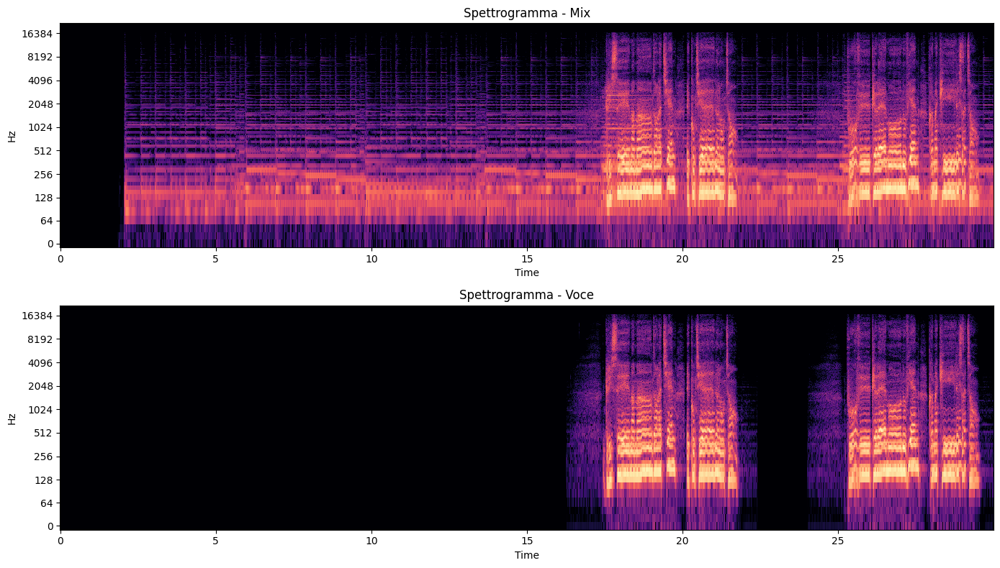

In [ ]:
mix_stft = librosa.stft(mix_mono, n_fft=N_FFT, hop_length=HOP_LENGTH)
vocals_stft = librosa.stft(vocals_mono, n_fft=N_FFT, hop_length=HOP_LENGTH)
mix_mag = np.abs(mix_stft)
vocals_mag = np.abs(vocals_stft)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
librosa.display.specshow(librosa.amplitude_to_db(mix_mag, ref=np.max),
                          sr=rate, hop_length=HOP_LENGTH, x_axis='time', y_axis='log', ax=axes[0])
axes[0].set_title('Spettrogramma - Mix')
librosa.display.specshow(librosa.amplitude_to_db(vocals_mag, ref=np.max),
                          sr=rate, hop_length=HOP_LENGTH, x_axis='time', y_axis='log', ax=axes[1])
axes[1].set_title('Spettrogramma - Voce')
plt.tight_layout()
plt.show()

## 3. Dataset e DataLoader

Il dataset carica una canzone alla volta da disco, estrae un segmento casuale, calcola spettrogrammi e la maschera target (Ideal Ratio Mask). Questo per evitare di occupare la RAM con l'intero dataset

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class MUSDBVocalDataset(Dataset):
    def __init__(self, root_dir, n_fft=2048, hop_length=512, segment_seconds=4, sr=44100):
        self.files = [os.path.join(root_dir, f) for f in os.listdir(root_dir) if f.endswith('.stem.mp4')]
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.segment_samples = segment_seconds * sr
        self.sr = sr

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        stems, rate = stempeg.read_stems(self.files[idx])

        mix = stems[0]
        vocals = stems[4]
        accompaniment = stems[1] + stems[2] + stems[3]

        total_samples = mix.shape[0]
        if total_samples > self.segment_samples:
            start = np.random.randint(0, total_samples - self.segment_samples)
            end = start + self.segment_samples
        else:
            start, end = 0, total_samples

        mix_mono = np.mean(mix[start:end], axis=1)
        vocals_mono = np.mean(vocals[start:end], axis=1)
        accompaniment_mono = np.mean(accompaniment[start:end], axis=1)

        if len(mix_mono) < self.segment_samples:
            pad = self.segment_samples - len(mix_mono)
            mix_mono = np.pad(mix_mono, (0, pad))
            vocals_mono = np.pad(vocals_mono, (0, pad))
            accompaniment_mono = np.pad(accompaniment_mono, (0, pad))

        mix_stft = librosa.stft(mix_mono, n_fft=self.n_fft, hop_length=self.hop_length)
        vocals_stft = librosa.stft(vocals_mono, n_fft=self.n_fft, hop_length=self.hop_length)
        accompaniment_stft = librosa.stft(accompaniment_mono, n_fft=self.n_fft, hop_length=self.hop_length)

        mix_mag = np.abs(mix_stft)
        vocals_mag = np.abs(vocals_stft)
        accompaniment_mag = np.abs(accompaniment_stft)

        epsilon = 1e-10
        mask = vocals_mag / (vocals_mag + accompaniment_mag + epsilon)

        mix_tensor = torch.from_numpy(mix_mag).float().unsqueeze(0)
        mask_tensor = torch.from_numpy(mask).float().unsqueeze(0)

        return mix_tensor, mask_tensor

train_dataset = MUSDBVocalDataset(TRAIN_PATH, n_fft=N_FFT, hop_length=HOP_LENGTH, segment_seconds=SEGMENT_SECONDS)
test_dataset = MUSDBVocalDataset(TEST_PATH, n_fft=N_FFT, hop_length=HOP_LENGTH, segment_seconds=SEGMENT_SECONDS)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2)

print("Canzoni train:", len(train_dataset), "- Canzoni test:", len(test_dataset))

batch_mix, batch_mask = next(iter(train_loader))
print("Shape batch mix:", batch_mix.shape)
print("Shape batch mask:", batch_mask.shape)

Canzoni train: 100 - Canzoni test: 50
Shape batch mix: torch.Size([4, 1, 1025, 345])
Shape batch mask: torch.Size([4, 1, 1025, 345])


## 4. Modello U-Net

Encoder-decoder con skip connections: comprime lo spettrogramma, poi lo ricostruisce fino a produrre una maschera (valori 0-1, via sigmoid) della stessa dimensione dell'input.

In [ ]:
import torch.nn as nn

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = self._conv_block(1, 16)
        self.enc2 = self._conv_block(16, 32)
        self.enc3 = self._conv_block(32, 64)
        self.enc4 = self._conv_block(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = self._conv_block(128, 256)
        self.up4 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec4 = self._conv_block(256, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec3 = self._conv_block(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = self._conv_block(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = self._conv_block(32, 16)
        self.out = nn.Conv2d(16, 1, kernel_size=1)

    def _conv_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(self._match_and_cat(self.up4(b), e4))
        d3 = self.dec3(self._match_and_cat(self.up3(d4), e3))
        d2 = self.dec2(self._match_and_cat(self.up2(d3), e2))
        d1 = self.dec1(self._match_and_cat(self.up1(d2), e1))
        return torch.sigmoid(self.out(d1))

    def _match_and_cat(self, upsampled, skip):
        diffY = skip.size(2) - upsampled.size(2)
        diffX = skip.size(3) - upsampled.size(3)
        upsampled = nn.functional.pad(upsampled, [diffX // 2, diffX - diffX // 2,
                                                     diffY // 2, diffY - diffY // 2])
        return torch.cat([upsampled, skip], dim=1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet().to(device)
print("Device:", device)
print("Numero parametri:", sum(p.numel() for p in model.parameters()))

Device: cuda
Numero parametri: 1943761


## 5. Training

Loss: errore quadratico medio (MSE) tra la maschera predetta e la maschera ideale (IRM). Ad ogni epoca salviamo un checkpoint del modello su Drive, così non si perde il lavoro in caso di disconnessione.

In [ ]:
import torch.optim as optim
import time

NUM_EPOCHS = 20
LEARNING_RATE = 1e-3

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Se esiste già un checkpoint, riprendi da lì invece di ripartire da zero
start_epoch = 0
checkpoint_path = os.path.join(CHECKPOINT_DIR, 'latest.pt')
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    print(f"Ripreso dal checkpoint, riparto dall'epoca {start_epoch}")
    if start_epoch >= NUM_EPOCHS:
        print("Training già completato: nessuna epoca da rifare.")

train_losses = []
val_losses = []

for epoch in range(start_epoch, NUM_EPOCHS):
    model.train()
    epoch_start = time.time()
    running_loss = 0.0

    for batch_mix, batch_mask in train_loader:
        batch_mix, batch_mask = batch_mix.to(device), batch_mask.to(device)

        optimizer.zero_grad()
        pred_mask = model(batch_mix)
        loss = criterion(pred_mask, batch_mask)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validazione veloce
    model.eval()
    val_running_loss = 0.0
    with torch.no_grad():
        for batch_mix, batch_mask in test_loader:
            batch_mix, batch_mask = batch_mix.to(device), batch_mask.to(device)
            pred_mask = model(batch_mix)
            val_running_loss += criterion(pred_mask, batch_mask).item()
    val_loss = val_running_loss / len(test_loader)
    val_losses.append(val_loss)

    print(f"Epoca {epoch+1}/{NUM_EPOCHS} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} - tempo: {time.time()-epoch_start:.1f}s")

    # Salvataggio checkpoint
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_loss': train_loss,
        'val_loss': val_loss,
    }, checkpoint_path)

Ripreso dal checkpoint, riparto dall'epoca 20
Training già completato: pesi caricati dal checkpoint, nessuna epoca da rifare.


In [ ]:
if train_losses:
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.xlabel('Epoca')
    plt.ylabel('MSE Loss')
    plt.title('Andamento del training')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("Nessuna loss registrata in questa sessione, il training è già stato fatto precedentemente.")

Nessuna loss registrata in questa sessione (training già completato in precedenza).


## 6. Valutazione con SDR

L'SDR (Signal to Distortion Ratio) è la metrica standard per la source separation: più è alto, meglio la voce stimata corrisponde a quella originale.

Per interpretare il valore del modello lo confrontiamo con due riferimenti, calcolati sugli stessi estratti: baseline dove il mix intero usato come "voce" (il livello minimo da battere) e oracolo che è la maschera ideale (IRM) applicata al mix, cioè il massimo ottenibile con questo approccio

La valutazione usa un estratto di 30 secondi per brano (a partire dal secondo 30) sui primi N brani del test set, e riporta la mediana. Non è una valutazione sul test set completo né sui brani interi.

In [ ]:
import museval

def separate_vocals(model, mix_audio, sr, n_fft=2048, hop_length=512, device='cpu'):
    """Applica il modello a un audio mono e restituisce la voce stimata."""
    mix_stft = librosa.stft(mix_audio, n_fft=n_fft, hop_length=hop_length)
    mix_mag = np.abs(mix_stft)
    mix_phase = np.angle(mix_stft)

    mix_tensor = torch.from_numpy(mix_mag).float().unsqueeze(0).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        pred_mask = model(mix_tensor).squeeze().cpu().numpy()

    estimated_vocals_mag = pred_mask * mix_mag
    estimated_vocals_stft = estimated_vocals_mag * np.exp(1j * mix_phase)
    return librosa.istft(estimated_vocals_stft, hop_length=hop_length)


def sdr_of(ref, est):
    """SDR mediano (dB) tra voce di riferimento e voce stimata."""
    n = min(len(ref), len(est))
    sdr, _, _, _ = museval.evaluate(ref[:n].reshape(1, -1, 1), est[:n].reshape(1, -1, 1))
    return np.nanmedian(sdr)


def evaluate_table(model, test_path, n_songs=10, excerpt_sec=30, start_sec=30, device='cpu'):
    """Per ogni brano: SDR di baseline, modello e oracolo su un estratto."""
    files = sorted(f for f in os.listdir(test_path) if f.endswith('.stem.mp4'))[:n_songs]
    results = []

    for fname in files:
        stems, rate = stempeg.read_stems(os.path.join(test_path, fname))
        total = stems.shape[1]
        s = min(start_sec * rate, max(0, total - excerpt_sec * rate))
        e = min(s + excerpt_sec * rate, total)

        mix = stems[0][s:e].mean(axis=1)
        voc = stems[4][s:e].mean(axis=1)
        acc = (stems[1] + stems[2] + stems[3])[s:e].mean(axis=1)
        del stems
        gc.collect()

        base = sdr_of(voc, mix)  # baseline: il mix come "voce"

        stft = lambda x: librosa.stft(x, n_fft=N_FFT, hop_length=HOP_LENGTH)
        M, V, A = stft(mix), stft(voc), stft(acc)
        irm = np.abs(V) / (np.abs(V) + np.abs(A) + 1e-10)
        oracle = sdr_of(voc, librosa.istft(irm * M, hop_length=HOP_LENGTH))  # maschera ideale

        mod = sdr_of(voc, separate_vocals(model, mix, rate, device=device))  # il modello

        results.append((base, mod, oracle))
        print(f"{fname[:40]:40s} baseline {base:6.2f} | modello {mod:6.2f} | oracolo {oracle:6.2f}")

    res = np.array(results)
    print("\n--- MEDIANA sulle canzoni (dB) ---")
    print(f"Baseline: {np.median(res[:,0]):.2f}   Modello: {np.median(res[:,1]):.2f}   Oracolo: {np.median(res[:,2]):.2f}")
    print("--- MEDIA sulle canzoni (dB) ---")
    print(f"Baseline: {res[:,0].mean():.2f}   Modello: {res[:,1].mean():.2f}   Oracolo: {res[:,2].mean():.2f}")
    print(f"Canzoni in cui il modello batte la baseline: {(res[:,1] > res[:,0]).sum()}/{len(res)}")
    return res

results = evaluate_table(model, TEST_PATH, n_songs=10, device=device)

AM Contra - Heart Peripheral.stem.mp4    baseline  -4.21 | modello  -1.36 | oracolo  13.52
Al James - Schoolboy Facination.stem.mp4 baseline  -1.57 | modello   4.05 | oracolo   9.66
Angels In Amplifiers - I'm Alright.stem. baseline  -2.88 | modello   3.17 | oracolo  10.99
Arise - Run Run Run.stem.mp4             baseline  -7.61 | modello  -2.16 | oracolo   8.83
BKS - Bulldozer.stem.mp4                 baseline -10.72 | modello  -6.94 | oracolo   9.12
BKS - Too Much.stem.mp4                  baseline  -1.67 | modello   3.71 | oracolo  13.03
Ben Carrigan - We'll Talk About It All T baseline  -7.36 | modello  -0.42 | oracolo   7.00
Bobby Nobody - Stitch Up.stem.mp4        baseline  -2.76 | modello   3.23 | oracolo   9.61
Buitraker - Revo X.stem.mp4              baseline -10.63 | modello  -8.89 | oracolo   8.12
Carlos Gonzalez - A Place For Us.stem.mp baseline  -1.76 | modello   2.62 | oracolo  10.85

--- MEDIANA sulle canzoni (dB) ---
Baseline: -3.55   Modello: 1.10   Oracolo: 9.64
--- ME

## 7. Inferenza su una traccia nuova

Carica un file audio tuo (mp3/wav) e prova a separare la voce con il modello addestrato.
Si elabora un estratto di soli 30 secondi per evitare la saturazione della RAM della sessione.

In [14]:
import soundfile as sf

YOUR_AUDIO_FILE = '/content/drive/MyDrive/AudioSeparation/alright.mp3'  # <-- cambia con il tuo file

# Solo 30 secondi, a partire dal secondo 60 (cambia offset per spostarti nel brano)
audio, sr_loaded = librosa.load(YOUR_AUDIO_FILE, sr=44100, mono=True, offset=60, duration=30)

estimated_vocals = separate_vocals(model, audio, sr_loaded, device=device)

print("Traccia originale:")
ipd.display(ipd.Audio(audio, rate=sr_loaded))
print("Voce isolata (stimata dal modello):")
ipd.display(ipd.Audio(estimated_vocals, rate=sr_loaded))

# Salvataggio su file
output_path = '/content/drive/MyDrive/AudioSeparation/voce_isolata.wav'
sf.write(output_path, estimated_vocals, sr_loaded)
print(f"Salvato in: {output_path}")

Traccia originale:


Voce isolata (stimata dal modello):


Salvato in: /content/drive/MyDrive/AudioSeparation/voce_isolata.wav
